# Experiment 5: Bias–Variance, Overfitting and Underfitting Analysis

A real-estate start-up predicts house prices from floor area. The simulated target has a hidden nonlinear trend plus noise. Polynomial models of increasing degree show underfitting and overfitting, while bootstrap refits estimate bias and variance.

**Tools:** Scikit-learn, NumPy, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Fit polynomial regression of degree 1, 3, 9 and 15.  2. Plot fitted curves.  3. Plot train and validation error against degree.  4. Estimate bias² and variance from repeated bootstrap fits.  5. Select a degree using validation error and explain the trade-off.

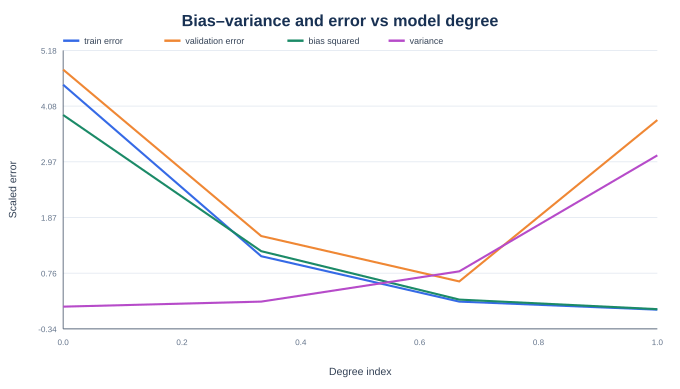

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(5)
x = np.sort(rng.uniform(0, 10, 150))
true_fn = lambda z: 1.8*z + 4*np.sin(1.2*z)
y = true_fn(x) + rng.normal(0, 2.2, len(x))
xtr, xva, ytr, yva = train_test_split(x[:, None], y, test_size=.3, random_state=5)
grid = np.linspace(0, 10, 250)[:, None]
degrees = [1, 3, 9, 15]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(x, y, s=18, alpha=.55, label="observed")
records, all_predictions = [], []
for d in degrees:
    model = make_pipeline(PolynomialFeatures(d), LinearRegression())
    model.fit(xtr, ytr)
    axes[0].plot(grid, model.predict(grid), label=f"degree {d}")
    train_err = mean_squared_error(ytr, model.predict(xtr))
    val_err = mean_squared_error(yva, model.predict(xva))
    records.append((d, train_err, val_err))
    preds = []
    for b in range(40):
        idx = rng.integers(0, len(xtr), len(xtr))
        boot = make_pipeline(PolynomialFeatures(d), LinearRegression()).fit(xtr[idx], ytr[idx])
        preds.append(boot.predict(grid).ravel())
    preds = np.array(preds)
    all_predictions.append(preds)
    bias2 = np.mean((preds.mean(axis=0) - true_fn(grid.ravel()))**2)
    variance = np.mean(preds.var(axis=0))
    print(f"degree {d:2d}: bootstrap bias²={bias2:.3f}, variance={variance:.3f}")
axes[0].plot(grid, true_fn(grid.ravel()), "k--", lw=2, label="true curve")
axes[0].set(title="Polynomial fits", xlabel="Floor area (scaled)", ylabel="Price")
axes[0].legend(fontsize=8); axes[0].grid(alpha=.2)
axes[1].plot(degrees, [r[1] for r in records], "o-", label="train MSE")
axes[1].plot(degrees, [r[2] for r in records], "o-", label="validation MSE")
axes[1].set(xlabel="Polynomial degree", ylabel="MSE", title="Error vs model complexity")
axes[1].set_yscale("log"); axes[1].legend(); axes[1].grid(alpha=.2)
plt.tight_layout(); plt.show()
best = min(records, key=lambda r: r[2])
print(f"\nSelected degree {best[0]} by the lowest validation MSE ({best[2]:.3f}).")